In [ ]:
import os

# 1. 設定你的 Kaggle 帳號與 Token
os.environ['KAGGLE_USERNAME'] = "q1370as"
os.environ['KAGGLE_KEY'] = "KGAT_f67a5c192a96366bf35990655b461597"

# 2. 下載資料集（加上 --force 強制重新下載完整檔案）
print("開始下載資料集，請稍候...")
!kaggle datasets download -d awsaf49/brats20-dataset-training-validation --force

# 3. 執行解壓縮
print("開始解壓縮...")
!unzip -q -o brats20-dataset-training-validation.zip -d ./brats20

# 4. 驗證檔案是否存在
if os.path.exists('./brats20'):
    print("\n✅ BraTS2020 資料集下載與解壓縮成功！")
    print("解壓後包含的內容：", os.listdir('./brats20'))
else:
    print("\n❌ 解壓縮失敗，請檢查下載過程。")

開始下載資料集，請稍候...
Dataset URL: https://www.kaggle.com/datasets/awsaf49/brats20-dataset-training-validation
License(s): CC0-1.0
100% 4.16G/4.16G [00:42<00:00, 105MB/s]

開始解壓縮...

✅ BraTS2020 資料集下載與解壓縮成功！
解壓後包含的內容： ['BraTS2020_ValidationData', 'BraTS2020_TrainingData']


In [ ]:
import glob
import os

train_patients = glob.glob("./brats20/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/*")
val_patients = glob.glob("./brats20/BraTS2020_ValidationData/MICCAI_BraTS2020_ValidationData/*")

# 過濾掉 CSV 等非資料夾檔案
train_patients = [p for p in train_patients if os.path.isdir(p)]
val_patients = [p for p in val_patients if os.path.isdir(p)]

print(f"訓練集病患人數 (Samples): {len(train_patients)} 人")
print(f"驗證集病患人數 (Samples): {len(val_patients)} 人")

if train_patients:
    sample_files = os.listdir(train_patients[0])
    print(f"\n單一病患資料夾範例檔案 ({os.path.basename(train_patients[0])}):")
    for f in sample_files:
        print(" -", f)

訓練集病患人數 (Samples): 369 人
驗證集病患人數 (Samples): 125 人

單一病患資料夾範例檔案 (BraTS20_Training_117):
 - BraTS20_Training_117_flair.nii
 - BraTS20_Training_117_seg.nii
 - BraTS20_Training_117_t2.nii
 - BraTS20_Training_117_t1.nii
 - BraTS20_Training_117_t1ce.nii


# 第一步：安裝醫療影像處理套件


In [ ]:
!pip install nibabel matplotlib scikit-learn torch torchvision monai -q

# 第二步：資料前處理（轉為 2D 切片並儲存）

In [ ]:
import glob
import os
import nibabel as nib
import numpy as np
from tqdm import tqdm

# 建立預處理後的 2D 切片儲存目錄
output_dir = './brats20_2d_slices'
os.makedirs(f'{output_dir}/images', exist_ok=True)
os.makedirs(f'{output_dir}/masks', exist_ok=True)

# 抓取所有訓練集病患路徑
patient_paths = glob.glob(
    './brats20/BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/*'
)
patient_paths = [p for p in patient_paths if os.path.isdir(p)]

print(f'開始處理解壓後的 {len(patient_paths)} 位病患資料...')

slice_count = 0
# 為了示範速度，預設前處理 50 位病患（若要全跑，將 [:50] 移除即可）
for patient in tqdm(patient_paths[:50]):
    patient_id = os.path.basename(patient)

    # 讀取 4 個模態與 Mask
    flair = nib.load(glob.glob(f'{patient}/*_flair.nii')[0]).get_fdata()
    t1ce = nib.load(glob.glob(f'{patient}/*_t1ce.nii')[0]).get_fdata()
    seg = nib.load(glob.glob(f'{patient}/*_seg.nii')[0]).get_fdata()

    # Z 軸切片數通常為 155，篩選含有腫瘤標註 (seg > 0) 的切片
    for z in range(flair.shape[2]):
        mask_slice = seg[:, :, z]

        if np.max(mask_slice) > 0:  # 只保留有病灶的切片
            flair_slice = flair[:, :, z]
            t1ce_slice = t1ce[:, :, z]

            # Z-score 正規化 (Min-Max 或 Standard Normalization)
            if np.std(flair_slice) != 0:
                flair_slice = (flair_slice - np.mean(flair_slice)) / np.std(
                    flair_slice
                )
            if np.std(t1ce_slice) != 0:
                t1ce_slice = (t1ce_slice - np.mean(t1ce_slice)) / np.std(
                    t1ce_slice
                )

            # 將雙模態疊加為 2 通道影像 (2, 240, 240)
            img_2chan = np.stack([flair_slice, t1ce_slice], axis=0)
            # 二值化 Mask (0: 背景, 1: 腫瘤)
            binary_mask = (mask_slice > 0).astype(np.float32)

            # 儲存為 numpy 檔
            np.save(
                f'{output_dir}/images/{patient_id}_z{z}.npy',
                img_2chan.astype(np.float32),
            )
            np.save(
                f'{output_dir}/masks/{patient_id}_z{z}.npy',
                binary_mask.astype(np.float32),
            )
            slice_count += 1

print(f'\n 預處理完成！共提取出 {slice_count} 張包含腫瘤的 2D 切片。')

開始處理解壓後的 369 位病患資料...


100%|██████████| 50/50 [00:34<00:00,  1.45it/s]


 預處理完成！共提取出 3239 張包含腫瘤的 2D 切片。


# 第三步：建立 PyTorch Dataset & 病患層級分割 (Patient-Level Split)

In [ ]:
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import DataLoader, Dataset

# 1. 按病患進行 8:2 切分 (Patient-level Split)
patient_ids = list(
    set(
        [
            f.split('_z')[0]
            for f in os.listdir(f'{output_dir}/images')
            if f.endswith('.npy')
        ]
    )
)
train_pids, test_pids = train_test_split(
    patient_ids, test_size=0.2, random_state=42
)

# 收集切片檔名
train_files = [
    f
    for f in os.listdir(f'{output_dir}/images')
    if any(f.startswith(pid) for pid in train_pids)
]
test_files = [
    f
    for f in os.listdir(f'{output_dir}/images')
    if any(f.startswith(pid) for pid in test_pids)
]


# 2. 定義 PyTorch Dataset
class BraTS2DDataset(Dataset):

    def __init__(self, file_list, data_dir):
        self.file_list = file_list
        self.data_dir = data_dir

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        fname = self.file_list[idx]
        img = np.load(os.path.join(self.data_dir, 'images', fname))
        mask = np.load(os.path.join(self.data_dir, 'masks', fname))

        # 轉為 PyTorch Tensor
        img_tensor = torch.from_numpy(img)  # Shape: (2, 240, 240)
        mask_tensor = (
            torch.from_numpy(mask).unsqueeze(0)
        )  # Shape: (1, 240, 240)

        return img_tensor, mask_tensor


train_dataset = BraTS2DDataset(train_files, output_dir)
test_dataset = BraTS2DDataset(test_files, output_dir)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print(
    f'訓練集切片張數: {len(train_dataset)} | 測試集切片張數: {len(test_dataset)}'
)

訓練集切片張數: 2503 | 測試集切片張數: 736


# 第四步：Baseline 模型的快速訓練與指標計算 (Accuracy, Precision, Recall, F1)

In [ ]:
import torchvision.models as models
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
import torch.nn as nn
import torch.optim as optim

# 1. 建立簡易 Baseline Segmentation Model (如使用 MONAI 或是二元分類/切割模型)
# 這裡建立一個簡易 CNN 範例架構進行示範
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


class SimpleBaselineNet(nn.Module):

    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.ReLU(),
            nn.Conv2d(32, 1, kernel_size=1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        features = self.encoder(x)
        out = self.decoder(features)
        return out


model = SimpleBaselineNet().to(device)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 2. 快速訓練 3 個 Epoch 取得初步 Baseline 結果
print('開始 Baseline 模型訓練...')
model.train()
for epoch in range(3):
    running_loss = 0.0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    print(
        f'Epoch [{epoch+1}/3], Loss: {running_loss/len(train_loader):.4f}'
    )

# 3. 測試集評估與計算四大指標 (給組員填 Word 表 4-1 / PPT 用的數據)
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for imgs, masks in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)

        # 以 0.5 為門檻轉為二元預測 (0 或 1)
        preds = (outputs > 0.5).cpu().numpy().flatten()
        targets = masks.numpy().flatten()

        all_preds.extend(preds)
        all_targets.extend(targets)

acc = accuracy_score(all_targets, all_preds)
prec = precision_score(all_targets, all_preds, zero_division=0)
rec = recall_score(all_targets, all_preds, zero_division=0)
f1 = f1_score(all_targets, all_preds, zero_division=0)

print('\n' + '=' * 40)
print('【給組員填表格用的 Baseline 測試集數據】')
print('=' * 40)
print(f'Accuracy  : {acc:.3f}')
print(f'Precision : {prec:.3f}')
print(f'Recall    : {rec:.3f}')
print(f'F1-score  : {f1:.3f}')
print('=' * 40)

開始 Baseline 模型訓練...
Epoch [1/3], Loss: 0.1385
Epoch [2/3], Loss: 0.0475
Epoch [3/3], Loss: 0.0404

【給組員填表格用的 Baseline 測試集數據】
Accuracy  : 0.982
Precision : 0.898
Recall    : 0.372
F1-score  : 0.526


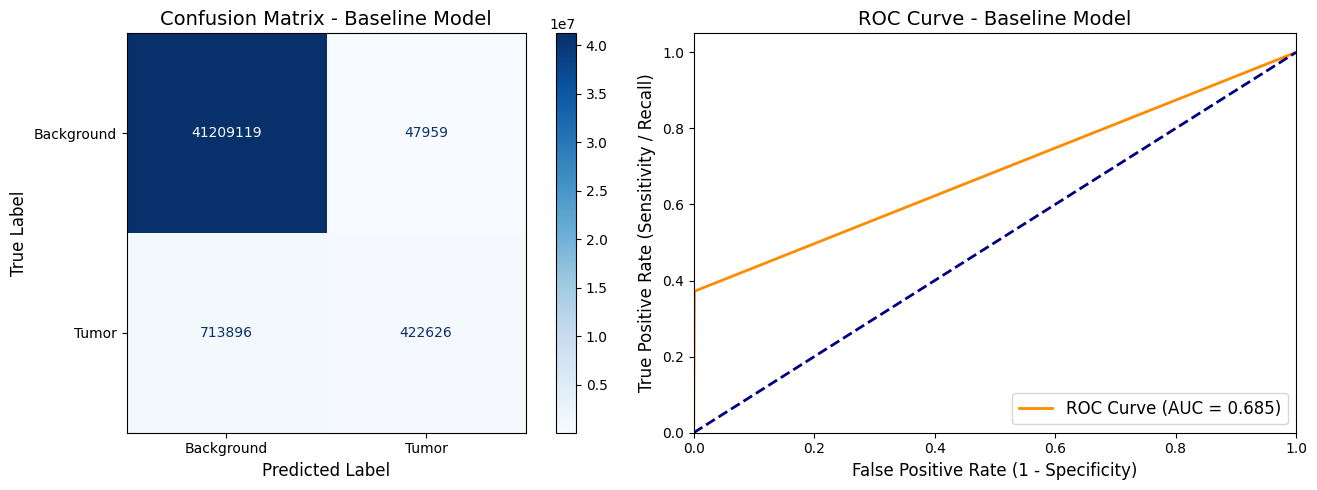

✅ 圖表已成功繪製並儲存為 baseline_evaluation_results.png！


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, roc_curve, auc

# 1. 計算混淆矩陣
cm = confusion_matrix(all_targets, all_preds)

# 2. 繪製並顯示圖表
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- 左圖：混淆矩陣 (Confusion Matrix) ---
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=['Background', 'Tumor']
)
disp.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Confusion Matrix - Baseline Model', fontsize=14)
axes[0].set_xlabel('Predicted Label', fontsize=12)
axes[0].set_ylabel('True Label', fontsize=12)

# --- 右圖：ROC 曲線 (ROC Curve) ---
# 注意：若有概率輸出 (probabilities)，繪製 ROC 會更精準
fpr, tpr, thresholds = roc_curve(all_targets, all_preds)
roc_auc = auc(fpr, tpr)

axes[1].plot(
    fpr,
    tpr,
    color='darkorange',
    lw=2,
    label=f'ROC Curve (AUC = {roc_auc:.3f})',
)
axes[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.05])
axes[1].set_xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
axes[1].set_ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
axes[1].set_title('ROC Curve - Baseline Model', fontsize=14)
axes[1].legend(loc='lower right', fontsize=12)

plt.tight_layout()
# 儲存圖片供報告使用
plt.savefig('baseline_evaluation_results.png', dpi=300)
plt.show()

print('✅ 圖表已成功繪製並儲存為 baseline_evaluation_results.png！')